In [1]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


(256, 256)


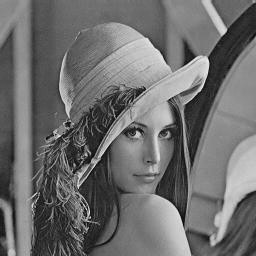

In [3]:
img = cv2.imread('/content/gdrive/My Drive/Colab26/Images/lena256.jpg')
RGB_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

gray_img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
print(gray_img.shape)
cv2_imshow(gray_img)

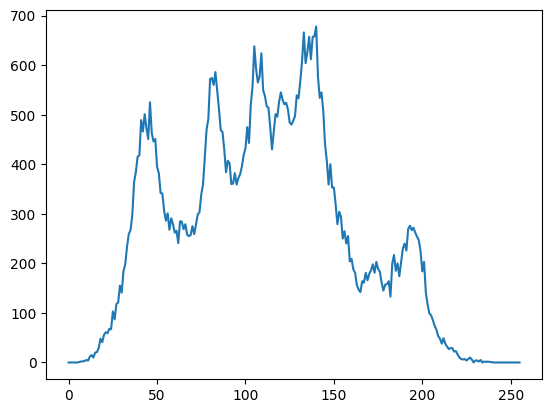

In [4]:
hist = cv2.calcHist([gray_img], [0], None, [256], [0, 256])
plt.plot(hist)

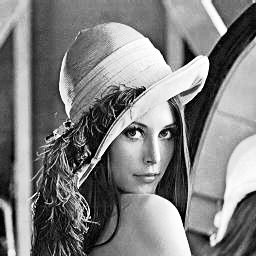

In [5]:
gray_Out = cv2.equalizeHist(gray_img)
cv2_imshow(gray_Out)

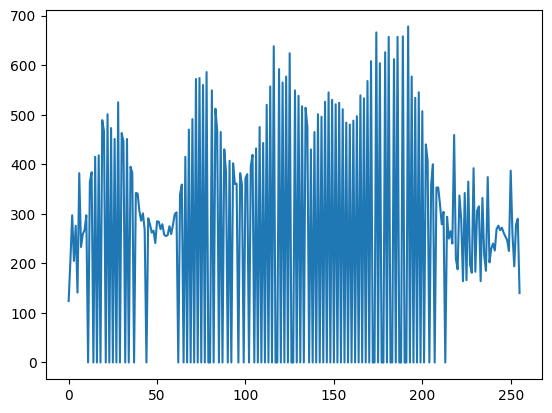

In [6]:
hist2 = cv2.calcHist([gray_Out], [0], None, [256], [0, 256])
plt.plot(hist2)

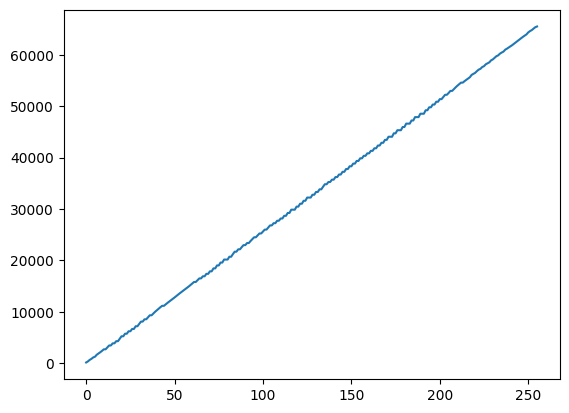

In [7]:
cumlHist = hist2.copy()
for i in range(1, len(cumlHist)):
  cumlHist[i] = cumlHist[i - 1] + hist2[i]

plt.plot(cumlHist)

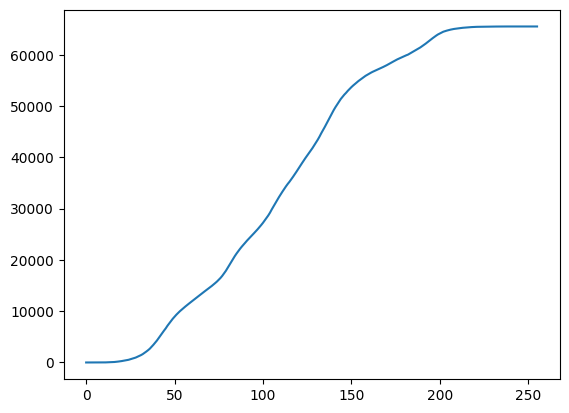

In [8]:
eqHist = hist.copy()

for i in range(len(eqHist)):
  eqHist[i] = eqHist[i - 1] + hist[i]

plt.plot(eqHist)

65536


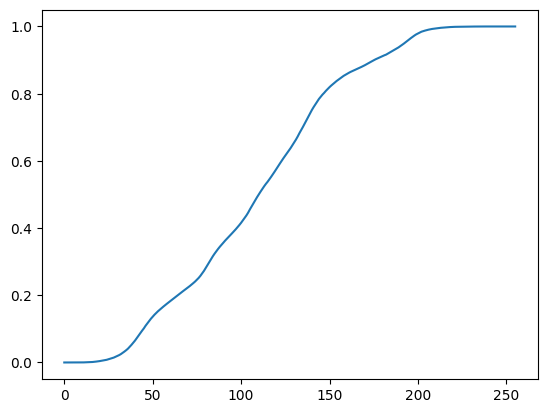

In [10]:
numOfPixels = np.int32(gray_img.shape[0] * gray_img.shape[1])
print(numOfPixels)

eqHist1 = eqHist / numOfPixels
plt.plot(eqHist1)

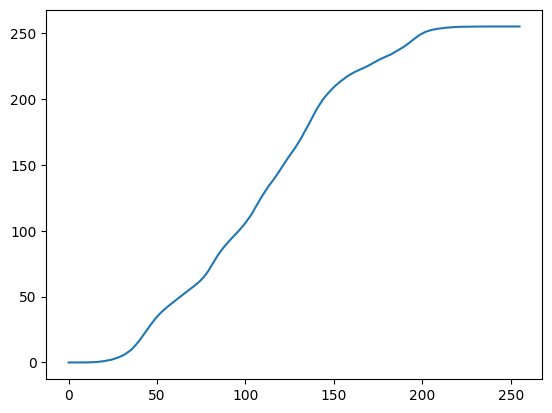

In [11]:
eqHist2 = eqHist1 * 255
plt.plot(eqHist2)

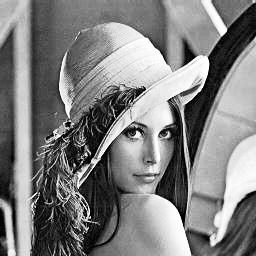

In [13]:
gray_Out1 = gray_img.copy()
for i in range(gray_img.shape[0]):
  for j in range(gray_img.shape[1]):
    gray_Out1[i, j] = eqHist2[gray_img[i, j]]

cv2_imshow(gray_Out1)

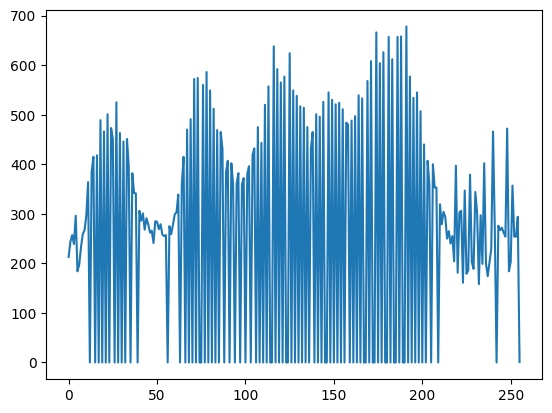

In [14]:
hist3 = cv2.calcHist([gray_Out1], [0], None, [256], [0, 256])
plt.plot(hist3)